# Measuring a scan: elements, dimensions, GD&T, datums and wall thickness

A metrology report turns a scan into numbers a drawing can be checked against (roadmap §7.1.4, §7.2, §7.3.4 and §7.5): `measure` fits named **elements** to regions or seeds, constructs more from them (an intersection line, an axis, a mid-plane), evaluates **dimensions** (distances and angles, each with a nominal and a tolerance) and **geometric tolerances** (form, orientation, location) under a least-squares or **minimum-zone** criterion, and reports PASS or FAIL per row. `align_datums` moves the part into the frame its datums define, and `thickness` measures a wall by a ray, an inscribed sphere or a cone of rays. Everything here runs in the C++ core; there is no numpy twin. See [measure](https://loumalouomega.github.io/meshioplusplus/measure) and [thickness](https://loumalouomega.github.io/meshioplusplus/thickness).

In [1]:
import os
import tempfile

import numpy as np
import matplotlib.pyplot as plt

import meshioplusplus as mp

try:
    import pyvista as pv
    pv.OFF_SCREEN = True
except ImportError:  # pragma: no cover
    pv = None

WORK = tempfile.mkdtemp()


def render(panels, title, size=(1500, 520), cmap='coolwarm', clim=None, rgb=False):
    """PyVista renders of (mesh, scalar or None, subtitle) panels, embedded
    through matplotlib; a matplotlib scatter when GL is unavailable."""
    try:
        if pv is None:
            raise RuntimeError('no pyvista')
        pl = pv.Plotter(off_screen=True, shape=(1, len(panels)), window_size=size)
        for i, (mesh, scalar, sub) in enumerate(panels):
            pl.subplot(0, i)
            path = os.path.join(WORK, f'view{i}.vtu')
            mp.write(path, mesh)
            grid = pv.read(path)
            if rgb and 'red' in grid.array_names:
                colours = np.stack([grid['red'], grid['green'], grid['blue']], axis=1)
                pl.add_mesh(grid, scalars=colours, rgb=True, show_edges=False)
            elif scalar is not None and scalar in grid.array_names:
                pl.add_mesh(grid, scalars=scalar, cmap=cmap, clim=clim, show_edges=False,
                            scalar_bar_args={'title': scalar})
            else:
                pl.add_mesh(grid, color='#90caf9', show_edges=True, edge_color='#1f4e79',
                            line_width=0.3)
            pl.add_text(sub, font_size=10)
            pl.camera_position = 'iso'
        img = pl.screenshot(return_img=True)
        pl.close()
        plt.figure(figsize=(15, 5.2))
        plt.imshow(img)
        plt.axis('off')
        plt.title(title)
        plt.tight_layout()
        plt.show()
    except Exception as exc:  # head-less GL fallback
        print('PyVista render skipped:', exc)
        fig = plt.figure(figsize=(15, 4.5))
        for i, (mesh, scalar, sub) in enumerate(panels):
            ax = fig.add_subplot(1, len(panels), i + 1, projection='3d')
            p = np.asarray(mesh.points)
            c = mesh.point_data[scalar] if scalar in mesh.point_data else p[:, 2]
            ax.scatter(p[:, 0], p[:, 1], p[:, 2], s=1, c=c, cmap=cmap)
            ax.set_title(sub)
        fig.suptitle(title)
        plt.tight_layout()
        plt.show()

## A scanned block with named faces

The part is a 60 x 40 x 20 block whose `xmax` face leans by 0.05 degrees, scanned with 0.004 of noise. Each face is a cell region (`bottom`, `top`, `xmin`, `xmax`, `ymin`, `ymax`), as a segmentation or a hand selection would leave it.

In [2]:
def grid_face(origin, u, v, nu, nv):
    pts = [origin + u * i / nu + v * j / nv for j in range(nv + 1) for i in range(nu + 1)]
    quads = [[j * (nu + 1) + i, j * (nu + 1) + i + 1, (j + 1) * (nu + 1) + i + 1, (j + 1) * (nu + 1) + i]
             for j in range(nv) for i in range(nu)]
    return np.array(pts, float), np.array(quads)


def scanned_block(L=60.0, W=40.0, H=20.0, tilt_deg=0.05, noise=0.004, seed=1):
    rng = np.random.default_rng(seed)
    d = H * np.tan(np.radians(tilt_deg))
    a = np.array
    faces = {'bottom': (a([0, 0, 0.0]), a([0, W, 0.0]), a([L, 0, 0.0])),
             'top': (a([0, 0, H]), a([L + d, 0, 0.0]), a([0, W, 0.0])),
             'xmin': (a([0, 0, 0.0]), a([0, 0, H]), a([0, W, 0.0])),
             'xmax': (a([L, 0, 0.0]), a([0, W, 0.0]), a([d, 0, H])),
             'ymin': (a([0, 0, 0.0]), a([L, 0, 0.0]), a([0, 0, H])),
             'ymax': (a([0, W, 0.0]), a([0, 0, H]), a([L, 0, 0.0]))}
    pts, quads, regions, offset, first = [], [], [], 0, 0
    for name, (origin, u, v) in faces.items():
        nu = max(4, int(np.linalg.norm(u) / 2))
        nv = max(4, int(np.linalg.norm(v) / 2))
        p, q = grid_face(origin, u, v, nu, nv)
        pts.append(p)
        quads.append(q + offset)
        regions.append((name, np.arange(first, first + len(q))))
        offset += len(p)
        first += len(q)
    p = np.vstack(pts)
    mesh = mp.Mesh(p + rng.normal(0, noise, p.shape), [('quad', np.vstack(quads))])
    mesh.regions = [mp.Region(name, 'cell', ids) for name, ids in regions]
    return mesh


scan = scanned_block()
print(len(scan.points), 'points,', sum(len(b.data) for b in scan.cells), 'cells,',
      [r.name for r in scan.regions])

2446 points, 2200 cells, ['bottom', 'top', 'xmin', 'xmax', 'ymin', 'ymax']


## Elements, dimensions and tolerances

The spec names four measured planes and one constructed element, the edge where `A` meets `B`; two dimensions with nominals; and three tolerances. `criterion="minimum_zone"` evaluates form and orientation zones by the minimum-zone fit (a linear programme, Chebyshev), which is never wider than the least-squares one.

In [3]:
spec = {
    'elements': [
        {'name': 'A', 'fit': 'plane', 'region': 'bottom'},
        {'name': 'B', 'fit': 'plane', 'region': 'xmax'},
        {'name': 'C', 'fit': 'plane', 'region': 'ymin'},
        {'name': 'T', 'fit': 'plane', 'region': 'top'},
        {'name': 'edge', 'construct': 'intersection', 'of': ['A', 'B']},
    ],
    'dimensions': [
        {'name': 'height', 'type': 'distance', 'between': ['A', 'T'], 'nominal': 20, 'tolerance': 0.01},
        {'name': 'corner', 'type': 'angle', 'between': ['A', 'B'], 'nominal': 90, 'tolerance': 0.02},
    ],
    'tolerances': [
        {'name': 'flat_A', 'type': 'flatness', 'feature': 'A', 'limit': 0.03},
        {'name': 'perp_B', 'type': 'perpendicularity', 'feature': 'B', 'datum': 'A', 'limit': 0.01},
        {'name': 'par_T', 'type': 'parallelism', 'feature': 'T', 'datum': 'A', 'limit': 0.05},
    ],
    'criterion': 'minimum_zone',
}
measured, report = mp.measure(scan, spec)
print(f"{'element':8s} {'kind':6s} {'points':>6s} {'form error':>11s}  source")
for e in report['elements']:
    form = '' if e['form_error'] is None else f"{e['form_error']:.4f}"
    print(f"{e['name']:8s} {e['kind']:6s} {e['num_points']:6d} {form:>11s}  {e['source']}")
print()
for row in report['dimensions'] + report['tolerances']:
    print(f"{row['name']:8s} {row['type']:17s} {row['value']:10.4f}  limit {row['tolerance']:<6g} "
          f"{'PASS' if row['pass'] else 'FAIL'}")
print('failed rows:', report['num_fail'])

element  kind   points  form error  source
A        plane     651      0.0215  fit:plane
B        plane     231      0.0186  fit:plane
C        plane     341      0.0195  fit:plane
T        plane     651      0.0212  fit:plane
edge     line        0              intersection

height   distance             20.0014  limit 0.01   PASS
corner   angle                89.9416  limit 0.02   FAIL
flat_A   flatness              0.0215  limit 0.03   PASS
perp_B   perpendicularity      0.0364  limit 0.01   FAIL
par_T    parallelism           0.0282  limit 0.05   PASS
failed rows: 2


The lean of `B` is 20 tan(0.05°) ≈ 0.017 over the face's height, so its perpendicularity zone to `A` and the corner angle both fail, while the height and the parallelism of the top pass. The deviation of each face from its own element shows the noise the form errors measure:

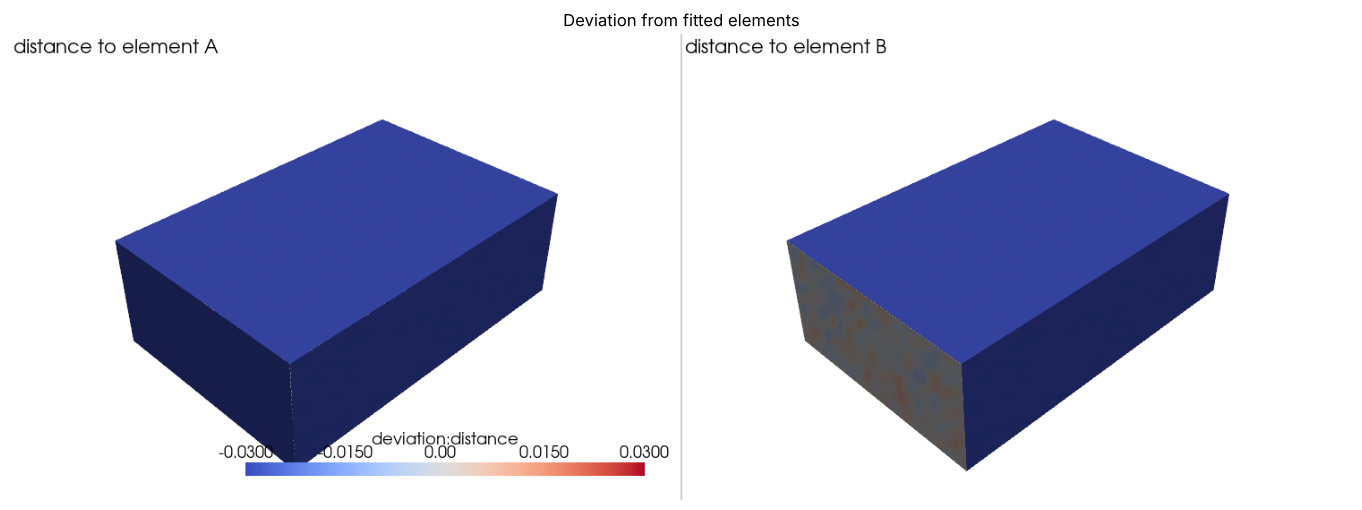

In [4]:
dev_a = mp.deviation(measured, measured, element='A', reference_region='bottom')
dev_b = mp.deviation(measured, measured, element='B', reference_region='xmax')
render([(dev_a, 'deviation:distance', 'distance to element A'),
        (dev_b, 'deviation:distance', 'distance to element B')],
       'Deviation from fitted elements', clim=(-0.03, 0.03))

## Least squares or minimum zone

The same flatness under both criteria: the minimum-zone fit (Carr and Ferreira's linear programme) finds the narrowest pair of parallel planes, the least-squares fit the plane of smallest squared residual, whose zone is wider.

In [5]:
for criterion in ('least_squares', 'minimum_zone'):
    _, rep = mp.measure(scan, {'elements': [{'name': 'A', 'fit': 'plane', 'region': 'bottom'}],
                               'tolerances': [{'name': 'flat', 'type': 'flatness', 'feature': 'A'}],
                               'criterion': criterion})
    print(f"{criterion:14s} flatness {rep['tolerances'][0]['value']:.5f}")

least_squares  flatness 0.02169
minimum_zone   flatness 0.02154


## Into the datum frame

`align_datums` builds the frame of a 3-2-1 alignment: the primary datum's plane becomes z = 0 with its outward normal as +z, the secondary's outward normal fixes +x, and the third element puts the origin on the corner, so this block, whose datums face down, out along x and out along -y, lands in the negative octant. The moved mesh carries the moved element table.

[[  1.       0.       0.     -59.9989]
 [  0.      -1.       0.      -0.0039]
 [  0.      -0.      -1.      -0.0021]
 [  0.       0.       0.       1.    ]]
bounds after: [-60.009 -40.017 -20.017] [0.03  0.009 0.011]


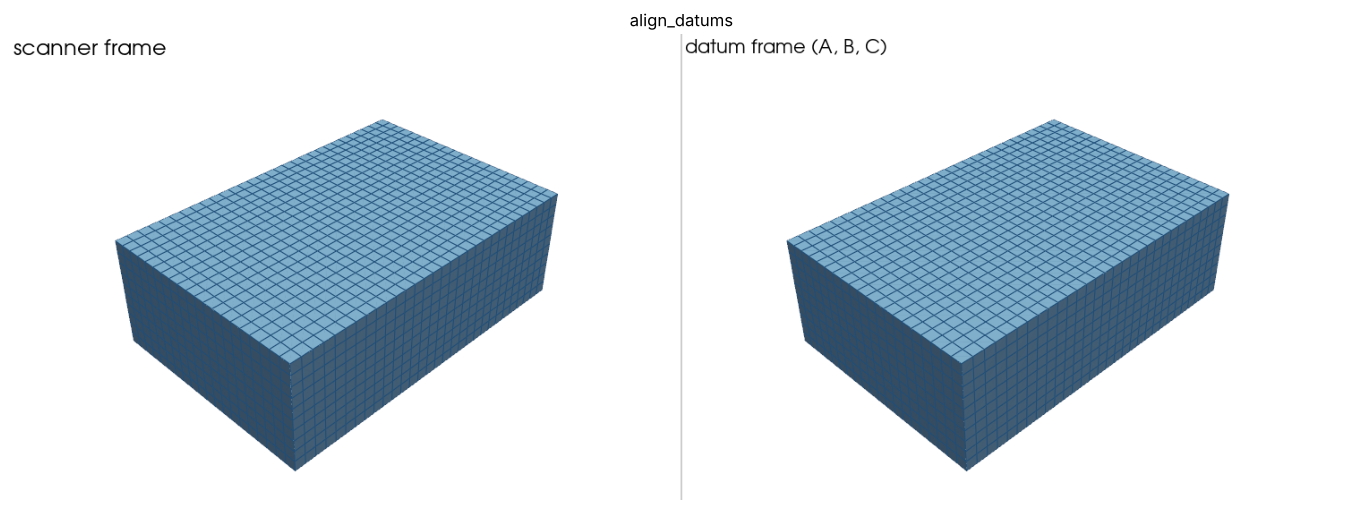

In [6]:
aligned, matrix = mp.align_datums(measured, 'A', 'B', origin='C')
np.set_printoptions(precision=4, suppress=True)
print(matrix)
print('bounds after:', np.asarray(aligned.points).min(axis=0).round(3), np.asarray(aligned.points).max(axis=0).round(3))
render([(scan, None, 'scanner frame'), (aligned, None, 'datum frame (A, B, C)')], 'align_datums')

## Wall thickness: ray, sphere and cone

A wedge plate, 1 thick at one end and 6 at the other, open along its sides. `method="ray"` shoots along the inward normal, `"sphere"` takes the largest empty sphere touching the face (twice its radius, the wall a calliper would read), and `"cone"` the shortest of a fan of rays within `cone_angle`. The ray reads a little more than the wall on the sloped face, where the sphere and the cone agree; the ray and the sphere miss at the open rim's last cells, where the cone still finds the far face.

ray    min 1.0625  p2 1.0708  p95 5.7318  mean 3.4824  missed 20
sphere min 1.0543  p2 1.0625  p95 5.6875  mean 3.4555  missed 20
cone   min 1.0548  p2 1.0627  p95 5.6927  mean 3.4876  missed 0


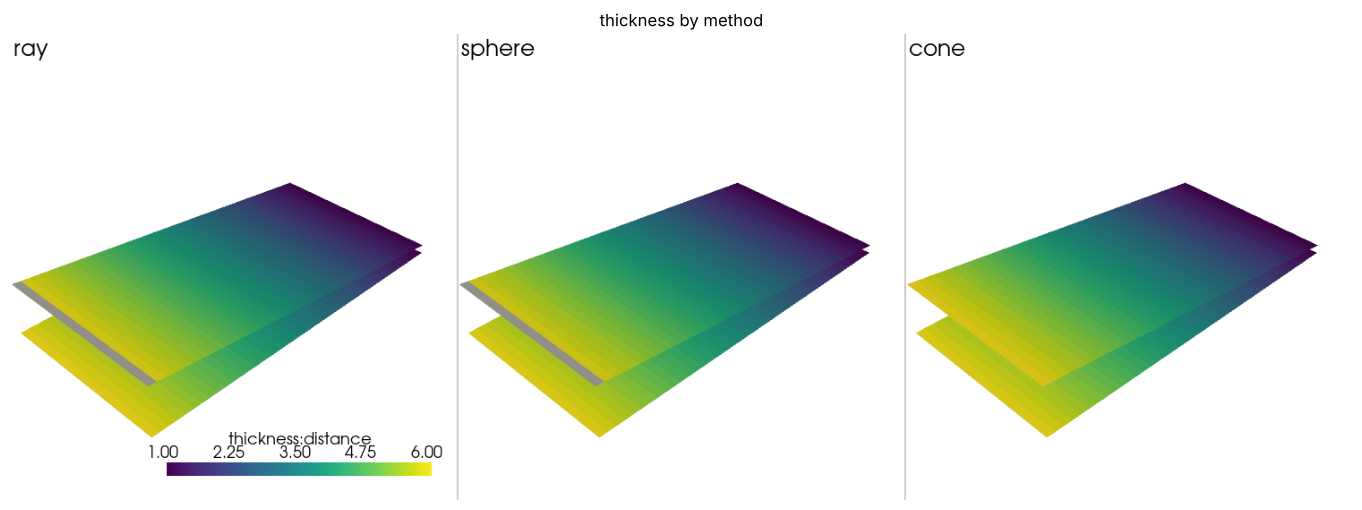

In [7]:
def wedge(L=40.0, W=20.0, h0=1.0, h1=6.0, n=40):
    a = np.array
    pts, quads, offset = [], [], 0
    for origin, u, v, nu, nv in ((a([0, 0, 0.0]), a([0, W, 0.0]), a([L, 0, 0.0]), n // 2, n),
                                 (a([0, 0, h0]), a([L, 0, h1 - h0]), a([0, W, 0.0]), n, n // 2)):
        p, q = grid_face(origin, u, v, nu, nv)
        pts.append(p)
        quads.append(q + offset)
        offset += len(p)
    return mp.Mesh(np.vstack(pts), [('quad', np.vstack(quads))])


plate = wedge()
panels = []
for method in ('ray', 'sphere', 'cone'):
    out, rep = mp.thickness(plate, method=method, return_report=True)
    print(f"{method:6s} min {rep['min']:.4f}  p2 {rep['p2']:.4f}  p95 {rep['p95']:.4f}  "
          f"mean {rep['mean']:.4f}  missed {rep['num_missed']}")
    panels.append((out, 'thickness:distance', method))
render(panels, 'thickness by method', clim=(1, 6), cmap='viridis')